In [2]:
%pip install xarray cfgrib eccodes netCDF4 dask matplotlib pandas numpy

  Using cached xarray-2026.9.0-py3-none-any.whl.metadata (12 kB)
  Using cached cfgrib-0.9.15.1-py3-none-any.whl.metadata (56 kB)
  Using cached eccodes-2.50.1-py3-none-any.whl.metadata (16 kB)
  Using cached netcdf4-1.7.5.1.post1-cp311-abi3-macosx_15_0_arm64.whl.metadata (1.7 kB)
  Using cached dask-2026.8.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached findlibs-0.1.5-py3-none-any.whl.metadata (4.3 kB)
  Using cached eccodeslib-2.50.0.34-cp312-cp312-macosx_15_0_arm64.whl.metadata (4.1 kB)
  Using cached cftime-1.6.6.1-cp311-abi3-macosx_11_0_arm64.whl.metadata (8.8 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached partd-1.4.2-py3-none-any.whl.metadata (4.6 kB)
  Using cached toolz-1.2.0-py3-none-any.whl.metadata (5.2 kB)
  Using cached locket-1.0.0-py2.py3-none-any.whl.metadata (2.8 kB)
  Using cached eckitlib-2.5.0.34-cp312-cp312-macosx_15_0_arm64.whl.metadata (3.5 kB)
Using cache

In [4]:
import numpy as np
import pandas as pd
import xarray as xr
import cfgrib
import matplotlib.pyplot as plt
from pathlib import Path

# Absolute path to your downloaded forecast
forecast_path = (
    Path.home()
    / "Files/thesis/ski_thesis_clean"
    / "inputs/seasonal_forecasts/ecmwf_202210_full_winter.grib"
)

print("File exists:", forecast_path.exists())
print("File location:", forecast_path)

ds = cfgrib.open_datasets(
    str(forecast_path),
    backend_kwargs={"indexpath": ""}
)[0]

ds

File exists: True
File location: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/seasonal_forecasts/ecmwf_202210_full_winter.grib


/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([o, ds], **kwargs)
/Users/evabenson/Files/thesis/snow_ml/venv/lib/python3.12/site-packages/cfgrib/xarray_store.py:51: FutureWarning: In a future version of xarray the default value for compat will change from compat='no_conflicts' to compat='override'. This is likely to lead to different results when combining overlapping variables with the same name. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set compat explicitly.
  o = xr.merge([

<xarray.Dataset> Size: 26MB
Dimensions:     (number: 51, step: 180, latitude: 14, longitude: 17)
Coordinates:
  * number      (number) int64 408B 0 1 2 3 4 5 6 7 ... 43 44 45 46 47 48 49 50
  * step        (step) timedelta64[ns] 1kB 1 days 2 days ... 179 days 180 days
    valid_time  (step) datetime64[ns] 1kB 2022-10-02 2022-10-03 ... 2023-03-30
  * latitude    (latitude) float64 112B 49.5 48.5 47.5 46.5 ... 38.5 37.5 36.5
  * longitude   (longitude) float64 136B -117.5 -116.5 -115.5 ... -102.5 -101.5
    time        datetime64[ns] 8B 2022-10-01
    surface     float64 8B 0.0
Data variables:
    mx2t24      (number, step, latitude, longitude) float32 9MB ...
    mn2t24      (number, step, latitude, longitude) float32 9MB ...
    tp          (number, step, latitude, longitude) float32 9MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [5]:
# Convert temperatures from Kelvin to Celsius
tmax = ds["mx2t24"] - 273.15
tmin = ds["mn2t24"] - 273.15
tmean = (tmax + tmin) / 2

# Convert cumulative precipitation to millimeters
tp_mm = ds["tp"] * 1000

# Estimate daily precipitation from cumulative totals
daily_precip = tp_mm.diff("step")

# Include the first forecast day
daily_precip = xr.concat(
    [tp_mm.isel(step=slice(0, 1)), daily_precip],
    dim="step"
).assign_coords(step=ds.step)

daily_precip = daily_precip.clip(min=0)

print("Temperature range (°C):",
      round(float(tmean.min()), 2),
      round(float(tmean.max()), 2))

print("Maximum daily precipitation (mm):",
      round(float(daily_precip.max()), 2))

Temperature range (°C): -38.7 26.45
Maximum daily precipitation (mm): 86.25


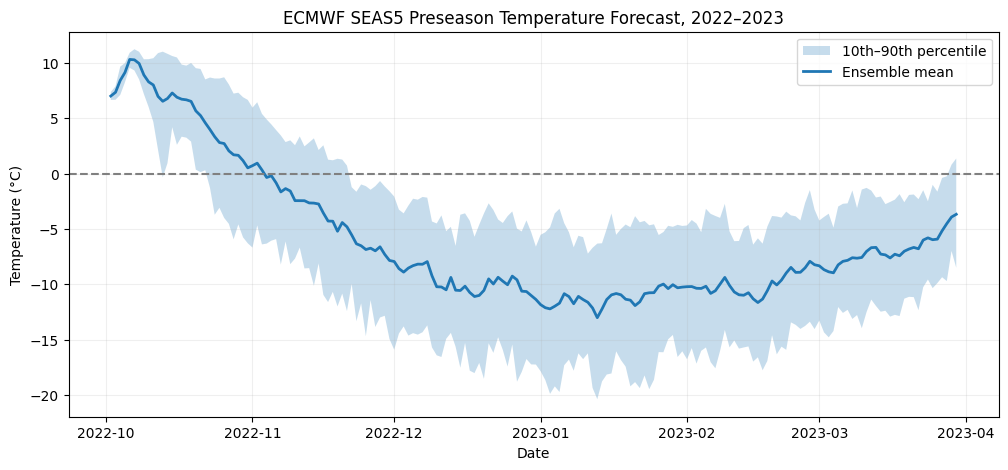

In [6]:
# Select a sample grid cell
cell = tmean.isel(latitude=5, longitude=5)

# Calculate ensemble statistics
ensemble_mean = cell.mean("number")
lower = cell.quantile(0.10, dim="number")
upper = cell.quantile(0.90, dim="number")

dates = pd.to_datetime(ds.valid_time.values)

plt.figure(figsize=(12, 5))

plt.fill_between(
    dates,
    lower.values,
    upper.values,
    alpha=0.25,
    label="10th–90th percentile"
)

plt.plot(
    dates,
    ensemble_mean.values,
    linewidth=2,
    label="Ensemble mean"
)

plt.axhline(0, linestyle="--", color="gray")

plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.title("ECMWF SEAS5 Preseason Temperature Forecast, 2022–2023")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [7]:
# Select November 1, 2022 through March 30, 2023
winter_start = np.datetime64("2022-11-01")
winter_end = np.datetime64("2023-03-30")

winter_mask = (
    (ds.valid_time >= winter_start) &
    (ds.valid_time <= winter_end)
)

# Build a dataset with converted climate variables
forecast = xr.Dataset({
    "tmax_c": tmax,
    "tmin_c": tmin,
    "tmean_c": tmean,
    "precip_mm": daily_precip
})

# Keep only November–March
winter_forecast = forecast.where(winter_mask, drop=True)

print("Winter forecast dimensions:")
print(dict(winter_forecast.sizes))

print("\nForecast dates:")
print(
    pd.to_datetime(
        ds.valid_time.where(winter_mask, drop=True).values
    )[[0, -1]]
)

Winter forecast dimensions:
{'number': 51, 'step': 150, 'latitude': 14, 'longitude': 17}

Forecast dates:
DatetimeIndex(['2022-11-01', '2023-03-30'], dtype='datetime64[ns]', freq=None)


In [8]:
# Calculate climate predictors for every ensemble member and grid cell
winter_predictors = xr.Dataset({
    "mean_temp_c": winter_forecast.tmean_c.mean("step"),
    "total_precip_mm": winter_forecast.precip_mm.sum("step"),
    "positive_degree_days": winter_forecast.tmean_c.clip(min=0).sum("step"),
    "freezing_degree_days": (-winter_forecast.tmean_c).clip(min=0).sum("step"),
    "thaw_days": (winter_forecast.tmax_c > 0).sum("step")
})

winter_predictors

<xarray.Dataset> Size: 292kB
Dimensions:               (number: 51, latitude: 14, longitude: 17)
Coordinates:
  * number                (number) int64 408B 0 1 2 3 4 5 ... 45 46 47 48 49 50
  * latitude              (latitude) float64 112B 49.5 48.5 47.5 ... 37.5 36.5
  * longitude             (longitude) float64 136B -117.5 -116.5 ... -101.5
    time                  datetime64[ns] 8B 2022-10-01
    surface               float64 8B 0.0
Data variables:
    mean_temp_c           (number, latitude, longitude) float32 49kB -6.982 ....
    total_precip_mm       (number, latitude, longitude) float32 49kB 610.9 .....
    positive_degree_days  (number, latitude, longitude) float32 49kB 8.009 .....
    freezing_degree_days  (number, latitude, longitude) float32 49kB 1.055e+0...
    thaw_days             (number, latitude, longitude) int64 97kB 35 29 ... 150

In [9]:
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"

for folder in ["inputs", "outputs"]:
    print(f"\n{folder.upper()} FILES")
    for path in sorted((root / folder).rglob("*")):
        if path.is_file() and path.suffix.lower() in [
            ".csv", ".geojson", ".shp", ".gpkg", ".parquet"
        ]:
            print(path.relative_to(root))


INPUTS FILES
inputs/consistent_model_data.csv
inputs/county_climate_panel_v4.csv
inputs/county_snodas_10cm_30cm_merged.csv
inputs/county_snodas_30cm_2000m.csv
inputs/county_warming_scenarios_all.csv

OUTPUTS FILES
outputs/final_sample_snow_summary.csv
outputs/historical_economic_analysis/county_gdp_regression_results.csv
outputs/historical_economic_analysis/county_snodas_gdp_panel.csv
outputs/historical_economic_analysis/nsaa_regression_results.csv
outputs/historical_economic_analysis/nsaa_snodas_regional_panel.csv
outputs/model_validation.csv
outputs/model_validation_predictions.csv
outputs/snodas_10cm_v4_november/snodas_state_warming_summary.csv
outputs/snodas_10cm_v4_november/snodas_validation.csv
outputs/snodas_10cm_v4_november/snodas_warming_day_changes.csv
outputs/snodas_10cm_v4_november/snodas_warming_predictions.csv
outputs/snodas_30cm_v4_november/snodas_state_warming_summary.csv
outputs/snodas_30cm_v4_november/snodas_validation.csv
outputs/snodas_30cm_v4_november/snodas_warmi

In [10]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"

files = [
    "inputs/consistent_model_data.csv",
    "inputs/county_climate_panel_v4.csv",
    "inputs/county_snodas_10cm_30cm_merged.csv",
    "outputs/train_v4.csv"
]

for file in files:
    df = pd.read_csv(root / file)

    print(f"\n{'='*65}")
    print(file)
    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())
    print("\nFirst 3 rows:")
    print(df.head(3).to_string(index=False))


inputs/consistent_model_data.csv
Shape: (400, 55)
Columns:
['fips', 'state', 'county', 'year', 'season_days', 'valid_days_all', 'snow_days_0cm_all', 'snow_days_5cm_all', 'snow_days_10cm_all', 'mean_depth_cm_all', 'peak_depth_cm_all', 'valid_fraction_all', 'valid_days_2000m', 'snow_days_0cm_2000m', 'snow_days_5cm_2000m', 'snow_days_10cm_2000m', 'mean_depth_cm_2000m', 'peak_depth_cm_2000m', 'valid_fraction_2000m', 'tmin_djf_all', 'tmax_djf_all', 'tmin_mar_all', 'tmax_mar_all', 'tmin_apr_all', 'tmax_apr_all', 'tmax_mar_apr_all', 'precip_on_all', 'precip_djf_all', 'precip_mar_apr_all', 'positive_degree_days_all', 'freezing_degree_days_all', 'thaw_days_all', 'precip_freezing_fraction_all', 'tmin_djf_2000m', 'tmax_djf_2000m', 'tmin_mar_2000m', 'tmax_mar_2000m', 'tmin_apr_2000m', 'tmax_apr_2000m', 'tmax_mar_apr_2000m', 'precip_on_2000m', 'precip_djf_2000m', 'precip_mar_apr_2000m', 'positive_degree_days_2000m', 'freezing_degree_days_2000m', 'thaw_days_2000m', 'precip_freezing_fraction_2000m',

In [11]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"

train = pd.read_csv(root / "outputs/train_v4.csv")

counties = (
    train[["fips", "state", "county", "mean_elev_m"]]
    .drop_duplicates(subset=["fips"])
    .sort_values(["state", "county"])
    .reset_index(drop=True)
)

counties["fips"] = counties["fips"].astype(int).astype(str).str.zfill(5)

print("Number of counties:", len(counties))
print(counties.to_string(index=False))

Number of counties: 20
 fips  state      county  mean_elev_m
08019      8 Clear Creek  3179.410654
08037      8       Eagle  2769.718166
08049      8       Grand  2832.750388
08051      8    Gunnison  2917.040085
08067      8    La Plata  2447.080327
08097      8      Pitkin  3050.032354
08107      8       Routt  2502.443626
08113      8  San Miguel  2428.897563
08117      8      Summit  3198.095458
16013     16      Blaine  1871.545540
16081     16       Teton  1991.349682
30029     30    Flathead  1503.906899
30031     30    Gallatin  1920.213070
30067     30        Park  2127.681772
49003     49   Box Elder  1479.734410
49035     49   Salt Lake  1718.879482
49043     49      Summit  2588.969218
49051     49     Wasatch  2458.551007
49057     49       Weber  1713.384971
56039     56       Teton  2458.576595


In [12]:
%pip install geopandas shapely pyogrio


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [13]:
import geopandas as gpd
import pandas as pd

# Census 2023 county boundaries
url = (
    "https://www2.census.gov/geo/tiger/GENZ2023/"
    "shp/cb_2023_us_county_500k.zip"
)

us_counties = gpd.read_file(url)

# Select our 20 counties using FIPS
target_fips = counties["fips"].tolist()

ski_counties = us_counties[
    us_counties["GEOID"].isin(target_fips)
].copy()

print("Counties matched:", len(ski_counties))

print(
    ski_counties[
        ["GEOID", "NAME", "STATEFP"]
    ].sort_values("GEOID").to_string(index=False)
)

Counties matched: 20
GEOID        NAME STATEFP
08019 Clear Creek      08
08037       Eagle      08
08049       Grand      08
08051    Gunnison      08
08067    La Plata      08
08097      Pitkin      08
08107       Routt      08
08113  San Miguel      08
08117      Summit      08
16013      Blaine      16
16081       Teton      16
30029    Flathead      30
30031    Gallatin      30
30067        Park      30
49003   Box Elder      49
49035   Salt Lake      49
49043      Summit      49
49051     Wasatch      49
49057       Weber      49
56039       Teton      56


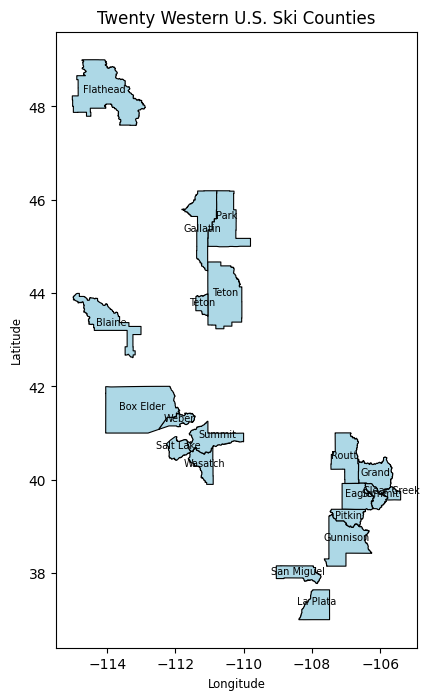

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 8))

ski_counties.plot(
    ax=ax,
    facecolor="lightblue",
    edgecolor="black",
    linewidth=0.8
)

for _, row in ski_counties.iterrows():
    centroid = row.geometry.representative_point()

    ax.annotate(
        row["NAME"],
        (centroid.x, centroid.y),
        fontsize=7,
        ha="center"
    )

ax.set_title("Twenty Western U.S. Ski Counties")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()

In [15]:
geo_dir = root / "inputs" / "geography"
geo_dir.mkdir(parents=True, exist_ok=True)

output_path = geo_dir / "ski_counties.geojson"

ski_counties.to_file(
    output_path,
    driver="GeoJSON"
)

print("Saved:", output_path)

Saved: /Users/evabenson/Files/thesis/ski_thesis_clean/inputs/geography/ski_counties.geojson


In [16]:
import geopandas as gpd
import numpy as np
import pandas as pd
from shapely.geometry import box

# Construct ECMWF grid cells from the forecast coordinates
lats = ds.latitude.values
lons = ds.longitude.values

lat_spacing = abs(np.diff(lats).mean())
lon_spacing = abs(np.diff(lons).mean())

grid_records = []

for lat in lats:
    for lon in lons:
        grid_records.append({
            "latitude": float(lat),
            "longitude": float(lon),
            "geometry": box(
                lon - lon_spacing / 2,
                lat - lat_spacing / 2,
                lon + lon_spacing / 2,
                lat + lat_spacing / 2
            )
        })

ecmwf_grid = gpd.GeoDataFrame(
    grid_records,
    geometry="geometry",
    crs="EPSG:4326"
)

# Use an equal-area projection for calculating overlap areas
area_crs = "EPSG:5070"

counties_area = ski_counties[
    ["GEOID", "NAME", "geometry"]
].to_crs(area_crs)

grid_area = ecmwf_grid.to_crs(area_crs)

# Calculate county/grid-cell intersections
overlaps = gpd.overlay(
    counties_area,
    grid_area,
    how="intersection",
    keep_geom_type=False
)

overlaps["overlap_km2"] = overlaps.geometry.area / 1e6

# Normalize overlap areas within each county
overlaps["weight"] = (
    overlaps["overlap_km2"] /
    overlaps.groupby("GEOID")["overlap_km2"].transform("sum")
)

print("Counties matched:", overlaps["GEOID"].nunique())
print("County/grid-cell intersections:", len(overlaps))

print(
    overlaps[
        ["GEOID", "NAME", "latitude", "longitude",
         "overlap_km2", "weight"]
    ].head(10).to_string(index=False)
)

Counties matched: 20
County/grid-cell intersections: 77
GEOID       NAME  latitude  longitude  overlap_km2   weight
08067   La Plata      37.5     -108.5  1142.820596 0.259592
08067   La Plata      37.5     -107.5  3251.971065 0.738687
08067   La Plata      36.5     -108.5     4.020512 0.000913
08067   La Plata      36.5     -107.5     3.553735 0.000807
08113 San Miguel      38.5     -109.5    63.068785 0.018895
08113 San Miguel      38.5     -108.5  1485.001088 0.444904
08113 San Miguel      38.5     -107.5   140.730648 0.042163
08113 San Miguel      37.5     -109.5    48.898522 0.014650
08113 San Miguel      37.5     -108.5  1179.841336 0.353479
08113 San Miguel      37.5     -107.5   420.259650 0.125909


In [17]:
records = []

for fips, group in overlaps.groupby("GEOID"):
    county_name = group["NAME"].iloc[0]

    for member in winter_predictors.number.values:
        result = {
            "fips": fips,
            "county": county_name,
            "year": 2023,
            "ensemble_member": int(member)
        }

        for variable in winter_predictors.data_vars:
            weighted_value = 0.0

            for _, cell in group.iterrows():
                value = winter_predictors[variable].sel(
                    number=member,
                    latitude=cell["latitude"],
                    longitude=cell["longitude"]
                ).item()

                weighted_value += value * cell["weight"]

            result[variable] = weighted_value

        records.append(result)

county_forecasts = pd.DataFrame(records)

# Add county characteristics
county_forecasts = county_forecasts.merge(
    counties[["fips", "state", "mean_elev_m"]],
    on="fips",
    how="left",
    validate="many_to_one"
)

print("Forecast records:", len(county_forecasts))
print("Counties:", county_forecasts.fips.nunique())
print("Ensemble members:", county_forecasts.ensemble_member.nunique())
print("Missing county information:", county_forecasts.mean_elev_m.isna().sum())

display(county_forecasts.head())

Forecast records: 1020
Counties: 20
Ensemble members: 51
Missing county information: 0


,fips,county,year,ensemble_member,mean_temp_c,total_precip_mm,positive_degree_days,freezing_degree_days,thaw_days,state,mean_elev_m
0,08019,Clear Creek,2023,0,-6.266404,148.243317,52.931366,992.891724,94.0,8,3179.410654
1,08019,Clear Creek,2023,1,-6.227923,157.989502,11.358551,945.546997,96.0,8,3179.410654
2,08019,Clear Creek,2023,2,-6.635405,193.038940,14.339081,1009.649780,89.0,8,3179.410654
3,08019,Clear Creek,2023,3,-4.525827,134.095795,75.662155,754.535889,104.0,8,3179.410654
4,08019,Clear Creek,2023,4,-5.473991,151.641846,36.285385,857.383911,102.0,8,3179.410654


In [18]:
output_dir = root / "outputs" / "seasonal_forecasts"
output_dir.mkdir(parents=True, exist_ok=True)

county_forecasts.to_csv(
    output_dir / "county_ecmwf_forecasts_2023.csv",
    index=False
)

print("County forecasts saved successfully.")

County forecasts saved successfully.


In [19]:
# Select December 2022 through February 2023
djf_mask = (
    (ds.valid_time >= np.datetime64("2022-12-01")) &
    (ds.valid_time <= np.datetime64("2023-02-28"))
)

djf_tmean = tmean.where(djf_mask, drop=True).mean("step")

# Calculate county-area-weighted DJF temperature
records = []

for fips, group in overlaps.groupby("GEOID"):
    for member in ds.number.values:
        weighted_temp = 0.0

        for _, cell in group.iterrows():
            value = djf_tmean.sel(
                number=member,
                latitude=cell["latitude"],
                longitude=cell["longitude"]
            ).item()

            weighted_temp += value * cell["weight"]

        records.append({
            "fips": fips,
            "ensemble_member": int(member),
            "ecmwf_djf_temp_c": weighted_temp
        })

djf_forecasts = pd.DataFrame(records)

# Average across ensemble members
djf_ensemble = (
    djf_forecasts.groupby("fips", as_index=False)
    ["ecmwf_djf_temp_c"].mean()
)

display(djf_ensemble.head())

,fips,ecmwf_djf_temp_c
0,08019,-7.554469
1,08037,-9.849860
2,08049,-8.280352
3,08051,-8.575593
4,08067,-6.814031


In [20]:
# Load observed Daymet climate data
daymet = pd.read_csv(
    root / "inputs/county_climate_panel_v4.csv"
)

# Standardize FIPS codes
daymet["fips"] = (
    daymet["fips"]
    .astype(int)
    .astype(str)
    .str.zfill(5)
)

# Select the 2022–2023 winter
observed = daymet[daymet["year"] == 2023].copy()

observed["daymet_djf_temp_c"] = (
    observed["tmin_djf_2000m"] +
    observed["tmax_djf_2000m"]
) / 2

# Merge observed and forecast temperatures
comparison = djf_ensemble.merge(
    observed[["fips", "county", "daymet_djf_temp_c"]],
    on="fips",
    how="inner"
)

comparison["forecast_error_c"] = (
    comparison["ecmwf_djf_temp_c"] -
    comparison["daymet_djf_temp_c"]
)

print("Counties compared:", len(comparison))
print(
    "Mean forecast error (°C):",
    round(comparison["forecast_error_c"].mean(), 2)
)

display(comparison)

Counties compared: 20
Mean forecast error (°C): -0.93


,fips,ecmwf_djf_temp_c,county,daymet_djf_temp_c,forecast_error_c
0,08019,-7.554469,Clear Creek,-6.729403,-0.825066
1,08037,-9.849860,Eagle,-6.404667,-3.445193
2,08049,-8.280352,Grand,-8.765547,0.485195
3,08051,-8.575593,Gunnison,-8.207496,-0.368097
4,08067,-6.814031,La Plata,-3.939366,-2.874665
5,08097,-9.396005,Pitkin,-7.084593,-2.311413
6,08107,-8.769710,Routt,-7.192418,-1.577292
7,08113,-5.839632,San Miguel,-4.867657,-0.971975
8,08117,-9.537450,Summit,-8.256790,-1.280660
9,16013,-7.490675,Blaine,-7.320262,-0.170413


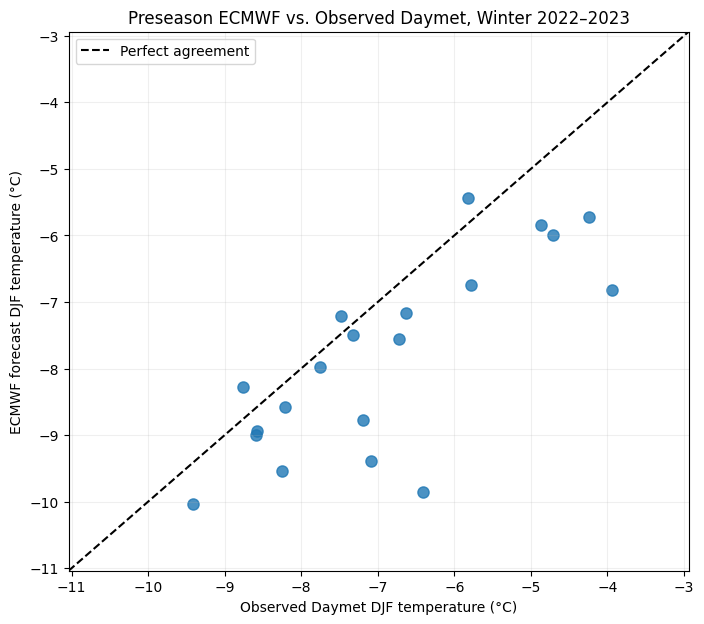

In [21]:
plt.figure(figsize=(8, 7))

plt.scatter(
    comparison["daymet_djf_temp_c"],
    comparison["ecmwf_djf_temp_c"],
    s=65,
    alpha=0.8
)

limits = [
    min(
        comparison["daymet_djf_temp_c"].min(),
        comparison["ecmwf_djf_temp_c"].min()
    ) - 1,
    max(
        comparison["daymet_djf_temp_c"].max(),
        comparison["ecmwf_djf_temp_c"].max()
    ) + 1
]

plt.plot(limits, limits, "k--", label="Perfect agreement")

plt.xlim(limits)
plt.ylim(limits)

plt.xlabel("Observed Daymet DJF temperature (°C)")
plt.ylabel("ECMWF forecast DJF temperature (°C)")
plt.title("Preseason ECMWF vs. Observed Daymet, Winter 2022–2023")

plt.grid(alpha=0.2)
plt.legend()
plt.show()

In [22]:
# Use winters before 2023 to construct historical climatology
historical = daymet[
    (daymet["year"] >= 2004) &
    (daymet["year"] <= 2022)
].copy()

historical["djf_temp_c"] = (
    historical["tmin_djf_2000m"] +
    historical["tmax_djf_2000m"]
) / 2

climatology = (
    historical.groupby("fips", as_index=False)
    ["djf_temp_c"]
    .mean()
    .rename(columns={
        "djf_temp_c": "historical_djf_temp_c"
    })
)

# Compare climatology and ECMWF against 2023 observations
validation = comparison.merge(
    climatology,
    on="fips",
    how="inner"
)

validation["climatology_error"] = (
    validation["historical_djf_temp_c"] -
    validation["daymet_djf_temp_c"]
)

validation["ecmwf_abs_error"] = (
    validation["forecast_error_c"].abs()
)

validation["climatology_abs_error"] = (
    validation["climatology_error"].abs()
)

print("Counties evaluated:", len(validation))

print(
    "ECMWF MAE:",
    round(validation["ecmwf_abs_error"].mean(), 3)
)

print(
    "Climatology MAE:",
    round(validation["climatology_abs_error"].mean(), 3)
)

display(
    validation[
        [
            "county",
            "daymet_djf_temp_c",
            "ecmwf_djf_temp_c",
            "historical_djf_temp_c",
            "ecmwf_abs_error",
            "climatology_abs_error"
        ]
    ]
)

Counties evaluated: 20
ECMWF MAE: 1.042
Climatology MAE: 1.086


,county,daymet_djf_temp_c,ecmwf_djf_temp_c,historical_djf_temp_c,ecmwf_abs_error,climatology_abs_error
0,Clear Creek,-6.729403,-7.554469,-5.909913,0.825066,0.819490
1,Eagle,-6.404667,-9.849860,-5.631272,3.445193,0.773396
2,Grand,-8.765547,-8.280352,-7.817828,0.485195,0.947719
3,Gunnison,-8.207496,-8.575593,-7.178201,0.368097,1.029294
4,La Plata,-3.939366,-6.814031,-2.698107,2.874665,1.241259
5,Pitkin,-7.084593,-9.396005,-6.170866,2.311413,0.913726
6,Routt,-7.192418,-8.769710,-6.145860,1.577292,1.046558
7,San Miguel,-4.867657,-5.839632,-3.692199,0.971975,1.175458
8,Summit,-8.256790,-9.537450,-7.545371,1.280660,0.711418
9,Blaine,-7.320262,-7.490675,-5.696566,0.170413,1.623695


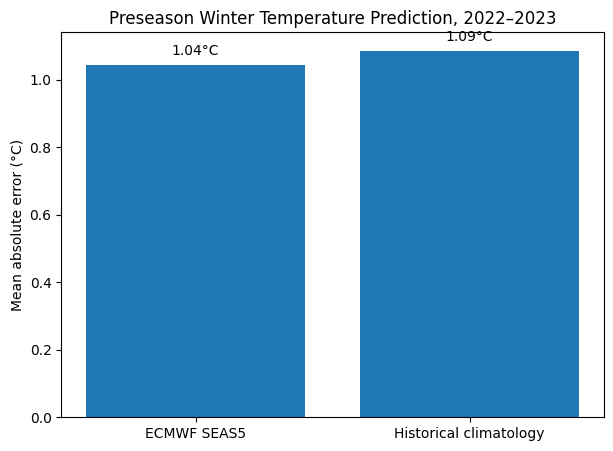

In [23]:
mae_ecmwf = validation["ecmwf_abs_error"].mean()
mae_clim = validation["climatology_abs_error"].mean()

plt.figure(figsize=(7, 5))

plt.bar(
    ["ECMWF SEAS5", "Historical climatology"],
    [mae_ecmwf, mae_clim]
)

plt.ylabel("Mean absolute error (°C)")
plt.title("Preseason Winter Temperature Prediction, 2022–2023")

for i, value in enumerate([mae_ecmwf, mae_clim]):
    plt.text(
        i,
        value + 0.03,
        f"{value:.2f}°C",
        ha="center"
    )

plt.show()

In [26]:
%pip install earthengine-api


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [28]:
import ee

ee.Initialize(project="fdos-491217")

print("Earth Engine initialized successfully!")

Earth Engine initialized successfully!


In [29]:
snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

print("Available bands:")
print(snodas.first().bandNames().getInfo())

print("\nFirst image properties:")
print(snodas.first().toDictionary().getInfo())

Available bands:
['SWE', 'Snow_Depth']

First image properties:
{'date_ingested': '2018-02-14'}


In [30]:
image = ee.Image(
    snodas.filterDate("2022-02-01", "2022-02-02").first()
)

print("Band information:")
print(image.getInfo()["bands"])

print("\nSnow depth sample statistics:")
print(
    image.select("Snow_Depth").reduceRegion(
        reducer=ee.Reducer.percentile([25, 50, 75, 95]),
        geometry=ee.Geometry.Point([-106.1, 39.6]).buffer(20000),
        scale=1000,
        maxPixels=1e7
    ).getInfo()
)

Band information:
[{'id': 'SWE', 'data_type': {'type': 'PixelType', 'precision': 'float'}, 'dimensions': [6935, 3351], 'crs': 'EPSG:4326', 'crs_transform': [0.008333333333333, 0, -124.733333333329, 0, -0.008333333333333, 52.8749999999978]}, {'id': 'Snow_Depth', 'data_type': {'type': 'PixelType', 'precision': 'float'}, 'dimensions': [6935, 3351], 'crs': 'EPSG:4326', 'crs_transform': [0.008333333333333, 0, -124.733333333329, 0, -0.008333333333333, 52.8749999999978]}]

Snow depth sample statistics:
{'Snow_Depth_p25': 0.4726837785315833, 'Snow_Depth_p50': 0.6519160911751289, 'Snow_Depth_p75': 0.8083048990129341, 'Snow_Depth_p95': 0.9887117659581538}


In [31]:
import ee
import pandas as pd
from pathlib import Path

ee.Initialize(project="fdos-491217")

root = Path.home() / "Files/thesis/ski_thesis_clean"

# Use exactly the counties in the final ML sample
train = pd.read_csv(
    root / "outputs/train_v4.csv",
    dtype={"fips": str}
)

fips = sorted(train["fips"].str.zfill(5).unique().tolist())

counties = (
    ee.FeatureCollection("TIGER/2018/Counties")
    .filter(ee.Filter.inList("GEOID", fips))
)

snodas = ee.ImageCollection(
    "projects/climate-engine/snodas/daily"
)

high_elevation = (
    ee.Image("USGS/SRTMGL1_003")
    .select("elevation")
    .gte(2000)
)

print("Counties in model:", len(fips))
print("Counties found in Earth Engine:", counties.size().getInfo())

Counties in model: 20
Counties found in Earth Engine: 20


In [32]:
def calculate_winter(year):

    year = ee.Number(year)

    # Winter ending in year t
    # Nov 1 (t-1) through Mar 30 (t), inclusive
    start = ee.Date.fromYMD(year.subtract(1), 11, 1)
    end = ee.Date.fromYMD(year, 3, 31)

    winter_images = snodas.filterDate(start, end)

    def classify_snow(image):

        snow = (
            image.select("Snow_Depth")
            .gt(0.30)
            .unmask(0)
            .rename("snow_days_30cm_2000m")
            .toFloat()
        )

        return snow

    snow_days = (
        winter_images
        .map(classify_snow)
        .sum()
        .updateMask(high_elevation)
    )

    results = snow_days.reduceRegions(
        collection=counties,
        reducer=ee.Reducer.mean(),
        scale=1000,
        tileScale=4
    )

    return results.map(
        lambda feature: ee.Feature(
            None,
            {
                "fips": feature.get("GEOID"),
                "county": feature.get("NAME"),
                "year": year,
                "snow_days_30cm_2000m": feature.get("mean"),
                "snodas_image_count": winter_images.size()
            }
        )
    )

In [33]:
test = calculate_winter(2023)

test_data = test.getInfo()

test_df = pd.DataFrame([
    feature["properties"]
    for feature in test_data["features"]
])

print("Rows:", len(test_df))
print("SNODAS images:", test_df["snodas_image_count"].unique())

display(
    test_df[
        ["county", "snow_days_30cm_2000m"]
    ].sort_values("snow_days_30cm_2000m", ascending=False)
)

Rows: 20
SNODAS images: [150]


,county,snow_days_30cm_2000m
13,Flathead,141.280690
10,Teton,138.719265
19,Teton,135.227073
9,Blaine,134.665028
16,Weber,134.021084
12,Gallatin,131.533332
11,Park,129.316025
17,Salt Lake,127.186505
0,Routt,122.488550
15,Box Elder,122.463171


In [34]:
# Extract 20 winters of November–March snow duration
years = ee.List.sequence(2004, 2023)

all_results = ee.FeatureCollection(
    years.map(calculate_winter)
).flatten()

# Export directly to Google Drive
task = ee.batch.Export.table.toDrive(
    collection=all_results,
    description="snodas_30cm_nov_mar_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="snodas_30cm_nov_mar_2004_2023",
    fileFormat="CSV",
    selectors=[
        "fips",
        "county",
        "year",
        "snow_days_30cm_2000m",
        "snodas_image_count"
    ]
)

task.start()

print("Export submitted!")
print("Task ID:", task.id)
print("Status:", task.status()["state"])

Export submitted!
Task ID: MBXJN65LXHZJBQYB6CMIEP6H
Status: READY


In [36]:
import ee

ee.Initialize(project="fdos-491217")

daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

image = ee.Image(
    daymet.filterDate(
        "2022-11-01",
        "2022-11-02"
    ).first()
)

print("Daymet bands:")
print(image.bandNames().getInfo())

print("\nAvailable images for winter 2023:")
print(
    daymet.filterDate(
        "2022-11-01",
        "2023-03-31"
    ).size().getInfo()
)

Daymet bands:
['dayl', 'prcp', 'srad', 'swe', 'tmax', 'tmin', 'vp']

Available images for winter 2023:
150


In [37]:
# Daymet daily weather collection
daymet = ee.ImageCollection("NASA/ORNL/DAYMET_V4")

def calculate_daymet_winter(year):

    year = ee.Number(year)

    start = ee.Date.fromYMD(year.subtract(1), 11, 1)
    end = ee.Date.fromYMD(year, 3, 31)

    winter = daymet.filterDate(start, end)

    def daily_variables(image):

        tmax = image.select("tmax")
        tmin = image.select("tmin")
        tmean = tmax.add(tmin).divide(2)

        return ee.Image.cat([
            tmean.rename("mean_temp_c"),
            image.select("prcp").rename("precip_mm"),
            tmean.max(0).rename("positive_degree_days"),
            tmean.multiply(-1).max(0).rename("freezing_degree_days"),
            tmax.gt(0).rename("thaw_days")
        ]).toFloat()

    daily = winter.map(daily_variables)

    # Aggregate daily weather over the winter
    seasonal = ee.Image.cat([
        daily.select("mean_temp_c").mean(),
        daily.select("precip_mm").sum(),
        daily.select("positive_degree_days").sum(),
        daily.select("freezing_degree_days").sum(),
        daily.select("thaw_days").sum()
    ]).updateMask(high_elevation)

    results = seasonal.reduceRegions(
        collection=counties,
        reducer=ee.Reducer.mean(),
        scale=1000,
        tileScale=4
    )

    return results.map(
        lambda feature: ee.Feature(
            None,
            {
                "fips": feature.get("GEOID"),
                "county": feature.get("NAME"),
                "year": year,
                "mean_temp_c": feature.get("mean_temp_c"),
                "total_precip_mm": feature.get("precip_mm"),
                "positive_degree_days": feature.get("positive_degree_days"),
                "freezing_degree_days": feature.get("freezing_degree_days"),
                "thaw_days": feature.get("thaw_days")
            }
        )
    )

In [38]:
test = calculate_daymet_winter(2023)

test_df = pd.DataFrame([
    feature["properties"]
    for feature in test.getInfo()["features"]
])

print("Rows:", len(test_df))

display(
    test_df[
        [
            "county",
            "mean_temp_c",
            "total_precip_mm",
            "positive_degree_days",
            "freezing_degree_days",
            "thaw_days"
        ]
    ].round(1)
)

Rows: 20


,county,mean_temp_c,total_precip_mm,positive_degree_days,freezing_degree_days,thaw_days
0,Routt,-6.2,490.3,27.9,956.8,68.0
1,San Miguel,-3.9,393.3,57.9,643.6,104.4
2,Gunnison,-6.9,390.7,21.6,1055.2,68.4
3,Grand,-7.7,319.6,16.3,1168.0,56.2
4,Summit,-7.4,356.0,13.0,1124.7,54.6
5,La Plata,-2.8,424.4,79.9,504.9,114.5
6,Clear Creek,-6.1,223.0,33.8,954.4,68.3
7,Eagle,-5.5,335.6,32.1,856.2,77.4
8,Pitkin,-6.2,492.7,25.0,960.4,71.4
9,Blaine,-6.8,482.4,7.1,1024.1,56.8


In [39]:
# Calculate historical November–March climate predictors
years = ee.List.sequence(2004, 2023)

all_daymet = ee.FeatureCollection(
    years.map(calculate_daymet_winter)
).flatten()

# Export to Google Drive
task = ee.batch.Export.table.toDrive(
    collection=all_daymet,
    description="daymet_nov_mar_2004_2023",
    folder="GEE_exports",
    fileNamePrefix="daymet_nov_mar_2004_2023",
    fileFormat="CSV",
    selectors=[
        "fips",
        "county",
        "year",
        "mean_temp_c",
        "total_precip_mm",
        "positive_degree_days",
        "freezing_degree_days",
        "thaw_days"
    ]
)

task.start()

print("Daymet export submitted!")
print("Task ID:", task.id)
print("Status:", task.status()["state"])

Daymet export submitted!
Task ID: P4TATFHPFANM22DYH54YMKFE
Status: READY


In [40]:
import pandas as pd
from pathlib import Path

root = Path.home() / "Files/thesis/ski_thesis_clean"

# Load historical weather
daymet = pd.read_csv(
    root / "inputs/daymet_nov_mar_2004_2023.csv",
    dtype={"fips": str}
)

# Load historical snow-cover outcomes
snow = pd.read_csv(
    root / "inputs/snodas_30cm_nov_mar_2004_2023.csv",
    dtype={"fips": str}
)

# Load terrain from original thesis dataset
original = pd.read_csv(
    root / "outputs/train_v4.csv",
    dtype={"fips": str}
)

terrain_cols = [
    "mean_elev_m",
    "mean_slope_deg",
    "mean_northness",
    "mean_eastness",
    "frac_above_2000m",
    "frac_above_2500m",
    "frac_above_3000m"
]

terrain = original[
    ["fips"] + terrain_cols
].drop_duplicates("fips")

# Merge datasets
model_data = (
    daymet
    .merge(
        snow[["fips", "year", "snow_days_30cm_2000m"]],
        on=["fips", "year"],
        validate="one_to_one"
    )
    .merge(
        terrain,
        on="fips",
        validate="many_to_one"
    )
)

# Save the new forecasting dataset
output_dir = root / "outputs/seasonal_forecasts"
output_dir.mkdir(parents=True, exist_ok=True)

model_data.to_csv(
    output_dir / "snow30_forecast_training_data.csv",
    index=False
)

print("Training dataset:", model_data.shape)
print("Counties:", model_data["fips"].nunique())
print("Years:", model_data["year"].min(), "-", model_data["year"].max())
print("Missing values:", model_data.isna().sum().sum())

display(model_data.head())

Training dataset: (400, 16)
Counties: 20
Years: 2004.0 - 2023.0
Missing values: 0


,fips,county,year,mean_temp_c,total_precip_mm,positive_degree_days,freezing_degree_days,thaw_days,snow_days_30cm_2000m,mean_elev_m,mean_slope_deg,mean_northness,mean_eastness,frac_above_2000m,frac_above_2500m,frac_above_3000m
0,08107,Routt,2004.0,-3.952133,372.408830,119.783816,716.555858,96.402369,77.934385,2502.443626,7.953817,0.022647,-0.051272,0.970197,0.487401,0.078055
1,08113,San Miguel,2004.0,-2.111847,280.185742,220.280224,539.169169,124.321351,54.296538,2428.897563,8.164218,0.147537,-0.140052,0.779811,0.394296,0.136663
2,08051,Gunnison,2004.0,-5.214242,239.430032,97.031277,884.381768,91.054085,68.422115,2917.040085,11.880236,-0.025878,-0.046593,0.998106,0.853398,0.405547
3,08049,Grand,2004.0,-5.515635,261.636004,75.743552,908.604384,85.520518,70.913944,2832.750388,10.154151,0.001380,0.002619,1.000000,0.813592,0.291119
4,08117,Summit,2004.0,-5.798175,259.819841,60.643816,936.168285,82.075996,78.188305,3198.095458,13.591981,0.107862,0.046445,1.000000,0.972990,0.674247


In [41]:
import numpy as np
import pandas as pd

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

weather_cols = [
    "mean_temp_c",
    "total_precip_mm",
    "positive_degree_days",
    "freezing_degree_days",
    "thaw_days"
]

features = weather_cols + terrain_cols
target = "snow_days_30cm_2000m"

# Historical training winters
train_data = model_data[model_data["year"] < 2023].copy()

# Held-out winter
test_data = model_data[model_data["year"] == 2023].copy()

model = XGBRegressor(
    n_estimators=300,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=10,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(
    train_data[features],
    train_data[target]
)

# Predictions using observed 2023 Daymet weather
test_data["predicted_snow_days"] = model.predict(
    test_data[features]
)

# Historical county-average baseline
county_climatology = (
    train_data.groupby("fips")[target].mean()
)

test_data["climatology_prediction"] = (
    test_data["fips"].map(county_climatology)
)

print("2023 held-out evaluation")
print("------------------------")

for name, prediction in [
    ("XGBoost (observed Daymet)", "predicted_snow_days"),
    ("Historical climatology", "climatology_prediction")
]:
    mae = mean_absolute_error(
        test_data[target],
        test_data[prediction]
    )

    rmse = np.sqrt(mean_squared_error(
        test_data[target],
        test_data[prediction]
    ))

    print(f"{name}: MAE = {mae:.2f} days, RMSE = {rmse:.2f} days")

print(
    "XGBoost R²:",
    round(r2_score(
        test_data[target],
        test_data["predicted_snow_days"]
    ), 3)
)

display(
    test_data[
        [
            "county",
            "fips",
            target,
            "predicted_snow_days",
            "climatology_prediction"
        ]
    ].round(1)
)

2023 held-out evaluation
------------------------
XGBoost (observed Daymet): MAE = 10.37 days, RMSE = 13.43 days
Historical climatology: MAE = 20.76 days, RMSE = 24.65 days
XGBoost R²: 0.634


,county,fips,snow_days_30cm_2000m,predicted_snow_days,climatology_prediction
380,Routt,08107,122.5,120.000000,97.3
381,San Miguel,08113,68.3,101.099998,48.7
382,Gunnison,08051,102.0,114.400002,89.6
383,Grand,08049,110.4,110.699997,94.4
384,Summit,08117,113.8,111.300003,105.2
385,La Plata,08067,75.7,83.900002,47.9
386,Clear Creek,08019,65.1,90.599998,72.7
387,Eagle,08037,99.4,107.800003,79.2
388,Pitkin,08097,116.0,124.900002,106.8
389,Blaine,16013,134.7,126.400002,107.8


In [42]:
# Load the ECMWF forecasts we previously generated
ecmwf = pd.read_csv(
    root / "outputs/seasonal_forecasts/county_ecmwf_forecasts_2023.csv",
    dtype={"fips": str}
)

ecmwf["fips"] = ecmwf["fips"].str.zfill(5)

# Average across the 51 ensemble members
ecmwf_mean = (
    ecmwf.groupby("fips", as_index=False)[weather_cols]
    .mean()
)

# Compare with observed 2023 Daymet
comparison = ecmwf_mean.merge(
    test_data[["fips", "county"] + weather_cols],
    on="fips",
    suffixes=("_ecmwf", "_daymet"),
    validate="one_to_one"
)

# Calculate differences
for variable in weather_cols:
    comparison[f"{variable}_difference"] = (
        comparison[f"{variable}_ecmwf"]
        - comparison[f"{variable}_daymet"]
    )

display(
    comparison[
        ["county", "fips"] +
        [f"{v}_difference" for v in weather_cols]
    ].round(1)
)

,county,fips,mean_temp_c_difference,total_precip_mm_difference,positive_degree_days_difference,freezing_degree_days_difference,thaw_days_difference
0,Clear Creek,08019,0.2,-75.9,8.0,-20.2,24.6
1,Eagle,08037,-2.8,-65.7,-22.4,399.4,-21.3
2,Grand,08049,1.0,-85.3,19.2,-128.2,15.4
3,Gunnison,08051,0.0,-141.4,1.7,0.3,8.0
4,La Plata,08067,-2.3,-94.8,-24.4,323.8,-29.1
5,Pitkin,08097,-1.6,-208.2,-10.5,227.2,-11.0
6,Routt,08107,-0.8,-209.5,2.7,126.6,-5.6
7,San Miguel,08113,0.2,-128.9,68.2,40.3,-3.7
8,Summit,08117,-0.6,-120.9,1.7,89.1,7.8
9,Blaine,16013,1.3,-184.3,63.7,-131.2,6.1


In [43]:
import numpy as np
import pandas as pd

# Inspect one ensemble member and one grid cell
tp = ds["tp"].isel(number=0, latitude=5, longitude=5)

values = tp.values * 1000  # Convert meters to mm

check = pd.DataFrame({
    "date": pd.to_datetime(ds.valid_time.values),
    "raw_tp_mm": values
})

check["change_mm"] = check["raw_tp_mm"].diff()

print("GRIB precipitation metadata:")
print(ds["tp"].attrs)

print("\nFirst 15 forecast days:")
display(check.head(15).round(3))

print("\nPrecipitation diagnostics:")
print("First value:", round(values[0], 3), "mm")
print("Last value:", round(values[-1], 3), "mm")
print("Maximum:", round(values.max(), 3), "mm")
print("Negative daily changes:", (check["change_mm"] < -0.01).sum())

GRIB precipitation metadata:
{'GRIB_paramId': 228, 'GRIB_dataType': 'fc', 'GRIB_numberOfPoints': 238, 'GRIB_typeOfLevel': 'surface', 'GRIB_stepUnits': 1, 'GRIB_stepType': 'instant', 'GRIB_gridType': 'regular_ll', 'GRIB_uvRelativeToGrid': 0, 'GRIB_NV': 0, 'GRIB_Nx': 17, 'GRIB_Ny': 14, 'GRIB_cfName': 'unknown', 'GRIB_cfVarName': 'tp', 'GRIB_gridDefinitionDescription': 'Latitude/Longitude Grid', 'GRIB_iDirectionIncrementInDegrees': 1.0, 'GRIB_iScansNegatively': 0, 'GRIB_jDirectionIncrementInDegrees': 1.0, 'GRIB_jPointsAreConsecutive': 0, 'GRIB_jScansPositively': 0, 'GRIB_latitudeOfFirstGridPointInDegrees': 49.5, 'GRIB_latitudeOfLastGridPointInDegrees': 36.5, 'GRIB_longitudeOfFirstGridPointInDegrees': -117.5, 'GRIB_longitudeOfLastGridPointInDegrees': -101.5, 'GRIB_missingValue': 3.4028234663852886e+38, 'GRIB_name': 'Total precipitation', 'GRIB_shortName': 'tp', 'GRIB_totalNumber': 0, 'GRIB_units': 'm', 'long_name': 'Total precipitation', 'units': 'm', 'standard_name': 'unknown'}

First 15 

/var/folders/m8/v5h3rz_n7_g1xddnytjvclc40000gn/T/ipykernel_70496/986276981.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(check.head(15).round(3))


,date,raw_tp_mm,change_mm
0,2022-10-02,0.549000,NaN
1,2022-10-03,2.213000,1.663
2,2022-10-04,2.262000,0.050
3,2022-10-05,2.262000,0.000
4,2022-10-06,2.262000,0.000
5,2022-10-07,2.312000,0.050
6,2022-10-08,2.434000,0.122
7,2022-10-09,2.670000,0.237
8,2022-10-10,2.907000,0.237
9,2022-10-11,7.080000,4.173



Precipitation diagnostics:
First value: 0.549 mm
Last value: 300.785 mm
Maximum: 300.785 mm
Negative daily changes: 0


In [44]:
# Examine accumulation behavior across the entire forecast
print("Total forecast days:", len(check))
print("First date:", check["date"].min())
print("Last date:", check["date"].max())

print("\nPrecipitation diagnostics:")
print("Final accumulated precipitation:", round(values[-1], 2), "mm")
print("Maximum accumulated precipitation:", round(values.max(), 2), "mm")
print("Negative daily changes:", (check["change_mm"] < -0.01).sum())

# Identify possible accumulation resets
resets = check[check["change_mm"] < -0.01]

display(resets.head(20))

Total forecast days: 180
First date: 2022-10-02 00:00:00
Last date: 2023-03-30 00:00:00

Precipitation diagnostics:
Final accumulated precipitation: 300.79 mm
Maximum accumulated precipitation: 300.79 mm
Negative daily changes: 0


,date,raw_tp_mm,change_mm


In [45]:
# Check precipitation accumulation across all ensemble members
# and grid cells, not just the single example

tp_all = ds["tp"]

# Difference along the forecast time dimension
time_dim = "valid_time" if "valid_time" in tp_all.dims else "step"

daily_changes = tp_all.diff(dim=time_dim)

negative_changes = (daily_changes < -1e-7).sum().item()
total_changes = daily_changes.count().item()

print("Precipitation accumulation check")
print("--------------------------------")
print("Dimensions:", dict(tp_all.sizes))
print("Total daily changes checked:", total_changes)
print("Negative changes:", negative_changes)
print(
    "Minimum daily change (mm):",
    round(float(daily_changes.min()) * 1000, 3)
)

Precipitation accumulation check
--------------------------------
Dimensions: {'number': 51, 'step': 180, 'latitude': 14, 'longitude': 17}
Total daily changes checked: 2172702
Negative changes: 6515
Minimum daily change (mm): -0.061


In [46]:
# Calculate ECMWF precipitation relative to Daymet
comparison["precip_ratio"] = (
    comparison["total_precip_mm_ecmwf"]
    / comparison["total_precip_mm_daymet"]
)

print("ECMWF / Daymet precipitation ratios")
print("-----------------------------------")
print(
    comparison["precip_ratio"]
    .describe()
    .round(3)
)

display(
    comparison[
        [
            "county",
            "fips",
            "total_precip_mm_ecmwf",
            "total_precip_mm_daymet",
            "precip_ratio"
        ]
    ]
    .sort_values("precip_ratio")
    .round(2)
)

ECMWF / Daymet precipitation ratios
-----------------------------------
count    20.000
mean      0.596
std       0.136
min       0.328
25%       0.517
50%       0.601
75%       0.669
max       0.804
Name: precip_ratio, dtype: float64


,county,fips,total_precip_mm_ecmwf,total_precip_mm_daymet,precip_ratio
15,Salt Lake,49035,298.77,910.95,0.33
18,Weber,49057,288.24,859.22,0.34
14,Box Elder,49003,194.19,441.24,0.44
12,Gallatin,30031,226.45,474.25,0.48
17,Wasatch,49051,308.77,637.02,0.48
13,Park,30067,223.89,424.65,0.53
16,Summit,49043,289.62,514.72,0.56
6,Routt,08107,280.77,490.27,0.57
5,Pitkin,08097,284.45,492.66,0.58
11,Flathead,30029,370.88,635.07,0.58


In [48]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Load ECMWF seasonal forecasts
# --------------------------------------------------

ecmwf = pd.read_csv(
    root / "outputs/seasonal_forecasts/county_ecmwf_forecasts_2023.csv",
    dtype={"fips": str}
)

ecmwf["fips"] = ecmwf["fips"].str.zfill(5)

# --------------------------------------------------
# 2. Add terrain variables used during training
# --------------------------------------------------

# Select only ECMWF weather variables to avoid
# duplicate terrain columns during the merge

ecmwf_model = ecmwf[
    ["fips", "ensemble_member"] + weather_cols
].merge(
    terrain,
    on="fips",
    validate="many_to_one"
)

print("ECMWF ensemble rows:", len(ecmwf_model))
print("Counties:", ecmwf_model["fips"].nunique())
print("Ensemble members:", ecmwf_model["ensemble_member"].nunique())
print("Missing features:", set(features) - set(ecmwf_model.columns))

# --------------------------------------------------
# 3. Predict snow-cover days for each ensemble member
# --------------------------------------------------

ecmwf_model["predicted_snow_days"] = model.predict(
    ecmwf_model[features]
)

# --------------------------------------------------
# 4. Summarize ensemble predictions by county
# --------------------------------------------------

ensemble_summary = (
    ecmwf_model.groupby("fips")["predicted_snow_days"]
    .agg(
        ensemble_mean="mean",
        ensemble_std="std",
        ensemble_min="min",
        ensemble_max="max"
    )
    .reset_index()
)

# --------------------------------------------------
# 5. Compare predictions with observed SNODAS
# --------------------------------------------------

forecast_results = test_data[
    ["fips", "county", target, "climatology_prediction"]
].merge(
    ensemble_summary,
    on="fips",
    validate="one_to_one"
)

# --------------------------------------------------
# 6. Calculate prediction accuracy
# --------------------------------------------------

print("\n2023 ECMWF preseason forecast evaluation")
print("----------------------------------------")

for name, prediction in [
    ("ECMWF + XGBoost", "ensemble_mean"),
    ("Historical climatology", "climatology_prediction")
]:
    mae = mean_absolute_error(
        forecast_results[target],
        forecast_results[prediction]
    )

    rmse = np.sqrt(mean_squared_error(
        forecast_results[target],
        forecast_results[prediction]
    ))

    print(f"{name}: MAE = {mae:.2f} days, RMSE = {rmse:.2f} days")

print(
    "ECMWF + XGBoost R²:",
    round(
        r2_score(
            forecast_results[target],
            forecast_results["ensemble_mean"]
        ), 3
    )
)

# --------------------------------------------------
# 7. Display county-level predictions
# --------------------------------------------------

forecast_results["forecast_error"] = (
    forecast_results["ensemble_mean"]
    - forecast_results[target]
)

display(
    forecast_results[
        [
            "county",
            "fips",
            target,
            "ensemble_mean",
            "ensemble_std",
            "climatology_prediction",
            "forecast_error"
        ]
    ].round(1)
)

# --------------------------------------------------
# 8. Save results
# --------------------------------------------------

output_dir = root / "outputs/seasonal_forecasts"
output_dir.mkdir(parents=True, exist_ok=True)

forecast_results.to_csv(
    output_dir / "ecmwf_xgboost_2023_uncalibrated.csv",
    index=False
)

ecmwf_model.to_csv(
    output_dir / "ecmwf_xgboost_2023_ensemble_predictions.csv",
    index=False
)

print("\nResults saved successfully.")

ECMWF ensemble rows: 1020
Counties: 20
Ensemble members: 51
Missing features: set()

2023 ECMWF preseason forecast evaluation
----------------------------------------
ECMWF + XGBoost: MAE = 19.57 days, RMSE = 23.32 days
Historical climatology: MAE = 20.76 days, RMSE = 24.65 days
ECMWF + XGBoost R²: -0.103


,county,fips,snow_days_30cm_2000m,ensemble_mean,ensemble_std,climatology_prediction,forecast_error
0,Routt,08107,122.5,103.500000,6.8,97.3,-19.0
1,San Miguel,08113,68.3,79.599998,17.6,48.7,11.3
2,Gunnison,08051,102.0,96.199997,6.4,89.6,-5.8
3,Grand,08049,110.4,95.900002,6.1,94.4,-14.5
4,Summit,08117,113.8,98.300003,4.5,105.2,-15.5
5,La Plata,08067,75.7,101.199997,12.4,47.9,25.5
6,Clear Creek,08019,65.1,78.199997,7.4,72.7,13.0
7,Eagle,08037,99.4,102.400002,5.6,79.2,3.0
8,Pitkin,08097,116.0,109.199997,6.3,106.8,-6.8
9,Blaine,16013,134.7,108.800003,11.4,107.8,-25.9



Results saved successfully.
